# Lost Circulation Prediction With Machine Learning

### Library Imports

In these opening cells, we import the core Python libraries for numerical computation (numpy), data manipulation (pandas), and plotting (matplotlib.pyplot, seaborn). We also bring in the machine learning utilities from scikit-learn for model splitting, scaling, and performance metrics, as well as the XGBoost classifier for gradient-boosted tree modeling. Then suppress warnings for a cleaner notebook display.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from xgboost import XGBClassifier
# from scipy.stats import norm

import warnings
warnings.filterwarnings('ignore')


### Initial Data Loading
 Next, we read the drilling dataset from new_drilling_data.csv into a DataFrame and preview its schema and first few rows. This establishes the foundation of our lost-circulation analysis by inspecting key drilling parameters such as depth, pore pressure, fracture pressure, mud weight, flow rate, and annular velocity.

In [2]:
df = pd.read_csv(r'new_drilling_data.csv')

df.head()

,depth,pore_pressure,fracture_pressure,mud_weight,flow_rate,annular_velocity,plastic_viscosity,yield_point,ecd,permeability,fluid_loss_rate
0,2498.160475,1132.287728,1783.221780,9.695648,908.341947,211.233280,16.066528,27.272467,9.721773,0.265876,1.247536
1,4802.857226,2158.696171,3206.380774,8.879271,696.710226,232.165281,35.712615,17.179046,8.912469,0.548603,0.367119
2,3927.975767,1708.207190,2852.983170,9.005437,517.279366,169.476981,21.232690,29.196957,9.023054,1.235119,2.006495
3,3394.633937,1612.368971,2298.625287,9.222685,841.985072,143.376810,22.098434,27.648362,9.240634,0.843270,0.157094
4,1624.074562,751.664009,1140.095826,9.314613,651.206881,147.826986,20.656132,28.782799,9.350770,1.195624,0.602230


### Label Generation via Physics-Guided Rules

Here, we define and apply a labeling function grounded in drilling physics. Based on equivalent circulating density (ECD) relative to fracture pressure and observed fluid loss rates, we classify each record into one of four categories: "Induced Fracture", "Severe Natural Fracture", "Moderate Natural Fracture", or "No Loss" (with any outliers marked "Unknown"). The generate_labels function encapsulates these conditional rules, augmenting the DataFrame with a new lost_circulation_type column to serve as model targets.

In [3]:
# Generate labels based on physics-guided rules
def generate_labels(df):
    conditions = [
        (df['ecd'] > df['fracture_pressure'] / (0.052 * df['depth'])) & (df['fluid_loss_rate'] > 50),
        (df['fluid_loss_rate'] > 20) & (df['fluid_loss_rate'] <= 50),
        (df['fluid_loss_rate'] > 5) & (df['fluid_loss_rate'] <= 20),
        (df['fluid_loss_rate'] <= 5)
    ]
    choices = ['Induced Fracture', 'Severe Natural Fracture', 'Moderate Natural Fracture', 'No Loss']
    df['lost_circulation_type'] = np.select(conditions, choices, default='Unknown')
    return df

In [4]:
# Generate labels
df = generate_labels(df)

df.head()

,depth,pore_pressure,fracture_pressure,mud_weight,flow_rate,annular_velocity,plastic_viscosity,yield_point,ecd,permeability,fluid_loss_rate,lost_circulation_type
0,2498.160475,1132.287728,1783.221780,9.695648,908.341947,211.233280,16.066528,27.272467,9.721773,0.265876,1.247536,No Loss
1,4802.857226,2158.696171,3206.380774,8.879271,696.710226,232.165281,35.712615,17.179046,8.912469,0.548603,0.367119,No Loss
2,3927.975767,1708.207190,2852.983170,9.005437,517.279366,169.476981,21.232690,29.196957,9.023054,1.235119,2.006495,No Loss
3,3394.633937,1612.368971,2298.625287,9.222685,841.985072,143.376810,22.098434,27.648362,9.240634,0.843270,0.157094,No Loss
4,1624.074562,751.664009,1140.095826,9.314613,651.206881,147.826986,20.656132,28.782799,9.350770,1.195624,0.602230,No Loss


### Class Distribution Analysis
This cell evaluates the prevalence of each lost circulation class. The large skew—dominated by "No Loss" cases—highlights an important challenge in drilling diagnostics: imbalanced data. These insights are critical when developing machine learning models that must remain sensitive to rare but costly events such as Induced Fractures.

In [5]:
df['lost_circulation_type'].value_counts()

lost_circulation_type
No Loss                      6910
Moderate Natural Fracture    2356
Severe Natural Fracture       583
Unknown                       145
Induced Fracture                6
Name: count, dtype: int64

### Physics-Guided Feature Engineering Functions

Before modeling, we codify essential physics-based calculations:

`calculate_fracture_pressure` estimates fracture pressure from overburden stress, pore pressure, and Poisson's ratio.

`calculate_fluid_loss_rate` models fluid invasion rates using permeability, viscosity, pressure drop, and formation damage.

`calculate_equivalent_circulating_density` computes ECD from mud weight, annular loss, and true vertical depth.

Additionally, `preprocess_data` standardizes selected continuous features (e.g., pore pressure, fracture pressure, rheological properties) using a `StandardScaler`—a critical step for algorithms sensitive to feature scale.

In [7]:
# Physics-guided functions
def calculate_fracture_pressure(depth, pore_pressure, poisson_ratio, overburden_stress):
    return ((poisson_ratio / (1 - poisson_ratio)) * (overburden_stress - pore_pressure) + pore_pressure)

def calculate_fluid_loss_rate(permeability, viscosity, pressure_differential, formation_damage_factor):
    return (permeability * pressure_differential) / (viscosity * formation_damage_factor)

def calculate_equivalent_circulating_density(mud_weight, annular_pressure_loss, true_vertical_depth):
    return mud_weight + (annular_pressure_loss / (0.052 * true_vertical_depth))

### Data Preprocessing for Modeling
Standardization is applied to all numerical features to ensure uniformity for machine learning. Variables like pore pressure, yield point, and ECD are scaled, which is crucial since models like XGBoost are sensitive to unscaled features when they vary significantly in magnitude.

In [8]:
# Data preprocessing 'depth'
def preprocess_data(df):
    scaler = StandardScaler()
    columns_to_scale = ['pore_pressure', 'fracture_pressure', 'mud_weight', 'flow_rate', 
                        'annular_velocity', 'plastic_viscosity', 'yield_point', 'ecd', 'permeability', 'fluid_loss_rate']
    df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
    return df, scaler

### Feature Preparation
To maintain quality labels, records with ambiguous class “Unknown” are excluded. The dataset is then split into features `X` and target labels `y`, with ‘depth’ also dropped since it may introduce bias or collinearity with pressure variables.

In [26]:
df = df[df['lost_circulation_type'] != 'Unknown']

df['lost_circulation_type'].value_counts()

lost_circulation_type
No Loss                      6910
Moderate Natural Fracture    2356
Severe Natural Fracture       583
Induced Fracture                6
Name: count, dtype: int64

In [111]:
df_processed, scaler = preprocess_data(df)

df_processed.shape

(9855, 12)

In [98]:
X = df_processed.drop(['lost_circulation_type', 'depth'], axis=1)
y = df_processed['lost_circulation_type']

print(X.shape)
X.head()

(9855, 10)


,pore_pressure,fracture_pressure,mud_weight,flow_rate,annular_velocity,plastic_viscosity,yield_point,ecd,permeability,fluid_loss_rate
0,-0.458360,-0.346592,-0.671962,1.193708,0.833992,-1.607072,1.086645,-0.681649,-0.690836,-0.455531
1,1.435329,1.412157,-1.378661,-0.029996,1.319002,1.144893,-1.220026,-1.381888,-0.539928,-0.562274
2,0.604192,0.975426,-1.269445,-1.067506,-0.133534,-0.883412,1.526452,-1.286206,-0.173494,-0.363513
3,0.427374,0.290347,-1.081384,0.810017,-0.738295,-0.762141,1.172549,-1.097949,-0.382647,-0.587738
4,-1.160598,-1.141371,-1.001806,-0.293106,-0.635181,-0.964174,1.431804,-1.002654,-0.194574,-0.533769


### Feature Encoding: One-Hot Encoding of Target Labels
A OneHotEncoder converts categorical labels into a format compatible with multi-class classifiers. This is essential for supporting algorithms like XGBoost which benefit from class probabilities. The encoder also stores the class names for later interpretability in reports and visualizations.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# One Hot Encoding
encoder = OneHotEncoder(sparse_output=False)

y_encoded = encoder.fit_transform(df[['lost_circulation_type']])

# Get class names
class_names = encoder.categories_[0]

class_names

array(['Induced Fracture', 'Moderate Natural Fracture', 'No Loss',
       'Severe Natural Fracture'], dtype=object)

In [73]:
print(y_encoded.shape)
y_encoded[:5]

(9855, 4)


array([[0., 0., 1., 0.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.]])

### Model Training

The train_and_evaluate_model function orchestrates data splitting (80/20 train/test), model instantiation (an XGBoost classifier with modest complexity to guard against overfitting), and training. Probabilistic outputs are converted to discrete class predictions, and overall accuracy is computed on the held-out test set. A reported accuracy of 99.80% provides an early indicator of the model's discriminative power—but must be contextualized against class imbalance.

In [79]:
# Updated model training and evaluation
def train_and_evaluate_model(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    model = XGBClassifier(n_estimators=2, max_depth=3, learning_rate=0.1, random_state=42)
    model.fit(X_train, y_train)
    
    y_pred_proba = model.predict_proba(X_test)
    y_pred = y_pred_proba.argmax(axis=1)
    y_test_classes = y_test.argmax(axis=1)

    accuracy = accuracy_score(y_test_classes, y_pred)
    print(f"Model Accuracy: {accuracy:.4f}")
    
    return model, X_test, y_test_classes, y_pred

In [88]:
# Train and evaluate model
model, X_test, y_test, y_pred = train_and_evaluate_model(X, y_encoded)

Model Accuracy: 0.9980


In [ ]:
train_and_evaluate_model(X, y)


In [54]:
y_test_classes[200:210]

array([2, 2, 2, 1, 2, 3, 2, 2, 2, 2], dtype=int64)

### In-Depth Evaluation Metrics
The classification report offers detailed metrics (precision, recall, F1-score) for each lost circulation class. While Induced Fracture shows poor performance (likely due to low sample size), the model performs near-perfectly for dominant classes. The confusion matrix offers visual confirmation—an essential diagnostic in operational decision support systems for drilling.

In [90]:
# Updated detailed model evaluation
def detailed_model_evaluation(y_test, y_pred, class_names):
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names))
    
    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    
    # Visualize confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [94]:
# y_test.values.value_counts()
np.unique(y_test, return_counts=True)

(array([0, 1, 2, 3], dtype=int64),
 array([   3,  459, 1390,  119], dtype=int64))

This cell quantifies the distribution of labels in the test split. The extreme imbalance is again visible: 1390 "No Loss" samples versus only 3 "Induced Fracture". This reiterates the challenge in classifying rare drilling events and may warrant future resampling strategies or cost-sensitive modeling.


Classification Report:
                           precision    recall  f1-score   support

         Induced Fracture       0.00      0.00      0.00         3
Moderate Natural Fracture       1.00      1.00      1.00       459
                  No Loss       1.00      1.00      1.00      1390
  Severe Natural Fracture       0.98      1.00      0.99       119

                 accuracy                           1.00      1971
                macro avg       0.74      0.75      0.75      1971
             weighted avg       1.00      1.00      1.00      1971


Confusion Matrix:
[[   0    0    0    3]
 [   0  459    0    0]
 [   0    1 1389    0]
 [   0    0    0  119]]


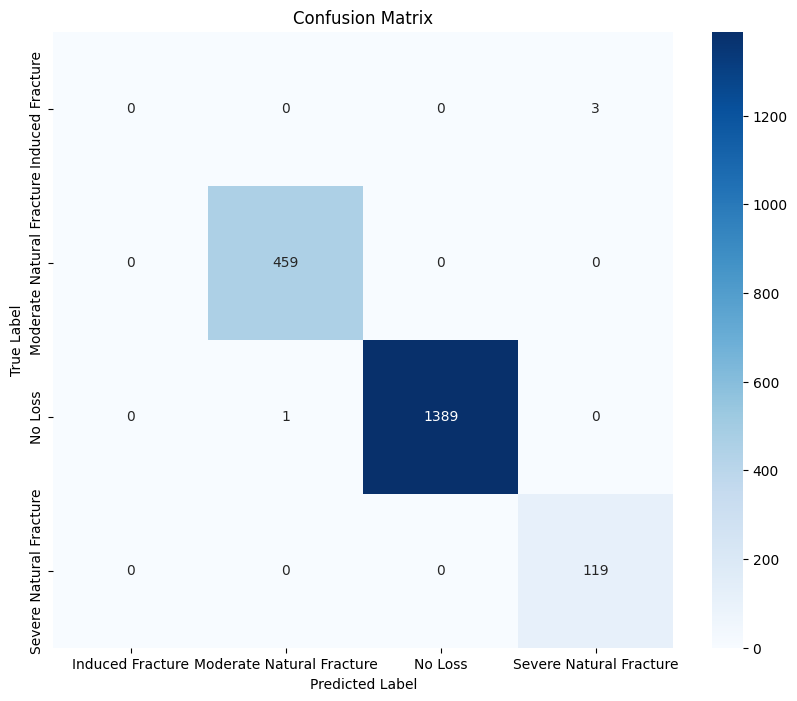

In [91]:
detailed_model_evaluation(y_test, y_pred, class_names)

### Real-Time Drilling Simulation Logic
A powerful simulation engine is built to mimic real-time drilling operations. At each depth increment, it generates synthetic drilling parameters, computes derived physics-based quantities like ECD and fluid loss, and runs predictions on the fly. This simulates the deployment of the ML model on a rigsite in a real-time advisory role.

In [103]:
# Real-time simulation
def simulate_real_time_drilling(model, scaler, n_steps=1000):
    current_depth = 1000
    depth_increment = 5
    results = []
    scaler = StandardScaler()
    for _ in range(n_steps):
        current_depth += depth_increment
        
        # Generate real-time data
        pore_pressure = current_depth * 0.465 * np.random.uniform(0.9, 1.1)
        overburden_stress = current_depth * 1.0 * np.random.uniform(0.95, 1.05)
        poisson_ratio = np.random.uniform(0.25, 0.35)
        fracture_pressure = calculate_fracture_pressure(current_depth, pore_pressure, poisson_ratio, overburden_stress)
        
        mud_weight = np.random.uniform(8.5, 12.5)
        flow_rate = np.random.uniform(400, 1000)
        annular_velocity = np.random.uniform(100, 250)
        plastic_viscosity = np.random.uniform(15, 40)
        yield_point = np.random.uniform(15, 30)
        
        ecd = calculate_equivalent_circulating_density(mud_weight, 
                                                       annular_velocity * plastic_viscosity / 1000, 
                                                       current_depth)
        
        permeability = np.random.lognormal(0, 1)
        formation_damage_factor = np.random.uniform(1, 5)
        
        fluid_loss_rate = calculate_fluid_loss_rate(permeability, 
                                                    plastic_viscosity, 
                                                    ecd * 0.052 * current_depth - pore_pressure,
                                                    formation_damage_factor)
        
        # Prepare input for model
        input_data = np.array([[pore_pressure, fracture_pressure, mud_weight, flow_rate,
                                annular_velocity, plastic_viscosity, yield_point, ecd, permeability, fluid_loss_rate]])
        
        scaled_input = scaler.fit_transform(input_data)
        
        # Make prediction
        prediction = model.predict(scaled_input)[0]
        probability = max(model.predict_proba(scaled_input)[0])
        
        results.append({
            'depth': current_depth,
            'predicted_class': prediction,
            'probability': probability,
            'ecd': ecd,
            'fluid_loss_rate': fluid_loss_rate
        })
        
    return pd.DataFrame(results)

### Running the Simulation
Using the model and feature scaler, a simulated drilling session is conducted over 1000 depth intervals. Each point logs predictions and the probability of lost circulation—emulating an intelligent surface system predicting downhole instability events as drilling progresses.

In [104]:
# Simulate real-time drilling
df_results = simulate_real_time_drilling(model, scaler)

In [107]:
df_results.head()

,depth,predicted_class,probability,ecd,fluid_loss_rate
0,1005,"[0.0, 0.0, 0.0, 0.0]",0.338648,9.249943,0.042521
1,1010,"[0.0, 0.0, 0.0, 0.0]",0.338648,11.337789,1.485459
2,1015,"[0.0, 0.0, 0.0, 0.0]",0.338648,11.249436,1.128323
3,1020,"[0.0, 0.0, 0.0, 0.0]",0.338648,12.413803,3.807874
4,1025,"[0.0, 0.0, 0.0, 0.0]",0.338648,9.093529,-1.952161


### Visualization of Simulation Results
The final plot visualizes lost circulation predictions across depth, using fluid loss rate as the key signal. This mimics real-time decision dashboards, allowing engineers to monitor trends and act proactively to prevent costly mud losses or well control issues.

In [108]:
# Visualization
def visualize_results(df_results):
    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=df_results, x='depth', y='fluid_loss_rate', hue='predicted_class', size='probability', sizes=(20, 200))
    plt.title('Lost Circulation Events During Drilling')
    plt.xlabel('Depth (ft)')
    plt.ylabel('Fluid Loss Rate (bbl/hr)')
    plt.show()

In [ ]:
# Visualize results
visualize_results(df_results)